In [1]:
import os
import re
import json
import random
import shutil
from datetime import datetime
from pathlib import Path
from typing import Optional, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.metrics import accuracy_score, f1_score

# -----------------------
# Dataset (ONLY this)
# -----------------------
DATA_PATH = r"HTTPS-clf-dataset.csv"  # <-- CHANGE ONLY THIS
LABEL_COL = "TYPE"  # <-- label col
DROP_COLS = ["Unnamed: 0"]  # <-- optional drops

# -----------------------
# Run folder (main folder)
# -----------------------
BASE_OUT_DIR = Path("v8")  # main folder
RUN_NAME = "https_ratio_v1"
DATASET_NAME = "HTTPS_CLF"

# -----------------------
# Split settings
# -----------------------
TEST_SIZE = 0.2
VAL_SIZE = 0.1
SEED = 42

# -----------------------
# Training settings
# -----------------------
BATCH_SIZE = 256
EPOCHS = 35
LR = 1e-3
WEIGHT_DECAY = 1e-4
EARLY_STOP_PATIENCE = 8

# -----------------------
# Preprocess settings (same spirit as ISCX notebook)
# -----------------------
CORR_THRESHOLD = 0.975
VT_THRESHOLD = 1e-5
SKEW_RATIO_THRESH = 1e3

# Optional: protect some key flow counters from being corr-dropped (dataset-specific)
PROTECT_COLS = set()

# -----------------------
# Imbalance control
# -----------------------
AUTO_SMOTE = True
SMOTE_K_NEIGHBORS = 5

# -----------------------
# Model defaults
# -----------------------
MODEL_DROP = 0.35
FOCAL_GAMMA = 1.5
LR_FACTOR = 0.5
LR_PATIENCE = 3

# -----------------------
# Unknown router
# -----------------------
DBSCAN_EPS = 0.7
DBSCAN_MIN_SAMPLES = 20

# -----------------------
# Device + seeds
# -----------------------
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------
# Paths (single source)
# -----------------------
RUN_DIR = BASE_OUT_DIR / RUN_NAME
paths = {
    "root": RUN_DIR,
    "cache": RUN_DIR / "cache",
    "logs": RUN_DIR / "logs",
    "preprocess": RUN_DIR / "preprocess",
    "models": RUN_DIR / "models",
    "plots": RUN_DIR / "plots",
}
for p in paths.values():
    if isinstance(p, Path):
        p.mkdir(parents=True, exist_ok=True)


# -----------------------
# Simple direct save helpers
# -----------------------
def save_json(path: Path, obj) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


def save_fig(path: Path, dpi: int = 200) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(path, dpi=dpi)


def reset_dir(path: Path) -> None:
    if path.exists():
        shutil.rmtree(path)
    path.mkdir(parents=True, exist_ok=True)


def safe_copy(src: Path, dst: Path) -> None:
    src = Path(src)
    dst = Path(dst)
    if not src.exists():
        return
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)


DEVICE: cuda
Artifacts root: v8\https_ratio_v1


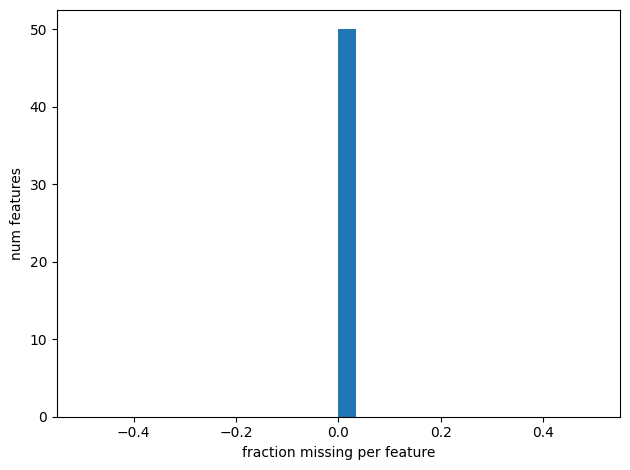

Rows: 145671
Dropped all-NaN engineered cols: 0
Ratio-engineered X_df shape: (145671, 50)


,prefix_duration,prefix_bytes_per_second,prefix_pkts_per_second,prefix_fwd_pkt_share,prefix_rev_pkt_share,prefix_fwd_byte_share,prefix_rev_byte_share,prefix_pkt_balance,prefix_byte_balance,prefix_dir_switch_rate,...,BRST_INTERVALS_STD,BRST_INTERVALS_25,BRST_INTERVALS_50,BRST_INTERVALS_75,BRST_DURATION_MEAN,BRST_DURATION_MAX,BRST_DURATION_STD,BRST_DURATION_25,BRST_DURATION_50,BRST_DURATION_75
0,0.033,993181.818182,909.090909,0.133333,0.866667,0.062822,0.937178,-0.733333,-0.874355,0.103448,...,0.000000,0.000,0.000,0.000,9.273000,9.273,0.000000,9.273,9.273,9.2730
1,0.067,511925.373134,447.761194,0.100000,0.900000,0.042625,0.957375,-0.800000,-0.914750,0.172414,...,0.000000,0.000,0.000,0.000,33.904000,33.904,0.000000,33.904,33.904,33.9040
2,0.050,778060.000000,600.000000,0.100000,0.900000,0.048737,0.951263,-0.800000,-0.902527,0.103448,...,0.234419,2.484,2.621,2.812,0.693125,3.465,1.056992,0.183,0.290,0.4405


prefix_duration            0.0
prefix_bytes_per_second    0.0
prefix_pkts_per_second     0.0
prefix_fwd_pkt_share       0.0
prefix_rev_pkt_share       0.0
prefix_fwd_byte_share      0.0
prefix_rev_byte_share      0.0
prefix_pkt_balance         0.0
prefix_byte_balance        0.0
prefix_dir_switch_rate     0.0
dtype: float64

[Rare Holdout] No rare labels below 3. Stratified split should work.


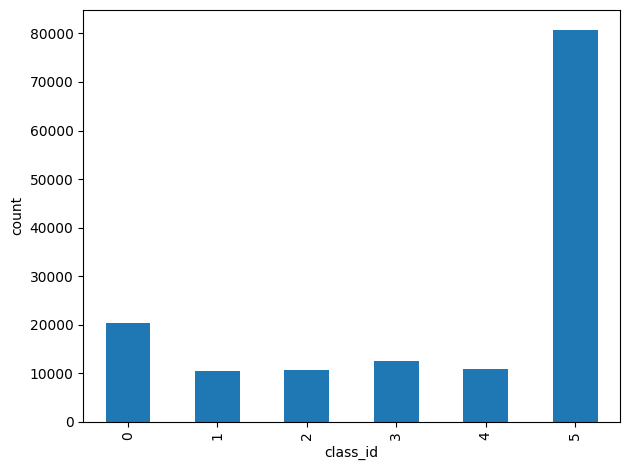

Final labeled dataset shape: (145671, 50)
n_classes: 6
min class count: 10373


In [2]:
config = {
    "DATA_PATH": DATA_PATH,
    "DATASET_NAME": DATASET_NAME,
    "RUN_NAME": RUN_NAME,
    "LABEL_COL": LABEL_COL,
    "DROP_COLS": DROP_COLS,
    "TEST_SIZE": TEST_SIZE,
    "VAL_SIZE": VAL_SIZE,
    "SEED": SEED,
    "BATCH_SIZE": BATCH_SIZE,
    "EPOCHS": EPOCHS,
    "LR": LR,
    "WEIGHT_DECAY": WEIGHT_DECAY,
    "EARLY_STOP_PATIENCE": EARLY_STOP_PATIENCE,
    "CORR_THRESHOLD": CORR_THRESHOLD,
    "VT_THRESHOLD": VT_THRESHOLD,
    "SKEW_RATIO_THRESH": SKEW_RATIO_THRESH,
    "PROTECT_COLS": sorted(list(PROTECT_COLS)),
    "AUTO_SMOTE": AUTO_SMOTE,
    "SMOTE_K_NEIGHBORS": SMOTE_K_NEIGHBORS,
    "MODEL_DROP": MODEL_DROP,
    "FOCAL_GAMMA": FOCAL_GAMMA,
    "LR_FACTOR": LR_FACTOR,
    "LR_PATIENCE": LR_PATIENCE,
    "DBSCAN_EPS": DBSCAN_EPS,
    "DBSCAN_MIN_SAMPLES": DBSCAN_MIN_SAMPLES,
}
save_json(paths["logs"] / "config.json", config)

print("DEVICE:", DEVICE)
print("Artifacts root:", paths["root"])

# ======================
# 1) Load + ratio/prefix feature engineering
# ======================
df = pd.read_csv(DATA_PATH)
df = df.drop_duplicates().reset_index(drop=True)

if LABEL_COL not in df.columns:
    raise ValueError(f"Label column '{LABEL_COL}' not found. Available columns: {list(df.columns)[:25]} ...")

BASE_STABLE_SUMMARY_COLS = [
    "PKT_LENGTHS_MEAN", "PKT_LENGTHS_MAX", "PKT_LENGTHS_STD",
    "PKT_LENGTHS_25", "PKT_LENGTHS_50", "PKT_LENGTHS_75",
    "INTERVALS_MEAN", "INTERVALS_MAX", "INTERVALS_STD",
    "INTERVALS_25", "INTERVALS_50", "INTERVALS_75",
    "BRST_INTERVALS_MEAN", "BRST_INTERVALS_MAX", "BRST_INTERVALS_STD",
    "BRST_INTERVALS_25", "BRST_INTERVALS_50", "BRST_INTERVALS_75",
    "BRST_DURATION_MEAN", "BRST_DURATION_MAX", "BRST_DURATION_STD",
    "BRST_DURATION_25", "BRST_DURATION_50", "BRST_DURATION_75",
]

RAW_ARRAY_SOURCE_COLS = [
    "PKT_LENGTHS", "PPI_PKT_DIRECTIONS", "PKT_TIMES",
    "DBI_BRST_BYTES", "DBI_BRST_PACKETS", "DBI_BRST_DURATION", "DBI_BRST_INTERVALS",
]

RAW_DROP_AFTER_ENGINEERING = [
    "Unnamed: 0",
    "BYTES", "BYTES_REV", "PACKETS", "PACKETS_REV", "BRST_COUNT", "REV_MORE",
    "TIME_INTERVALS",
    "DBI_BRST_BYTES", "DBI_BRST_PACKETS", "PKT_LENGTHS", "PPI_PKT_DIRECTIONS",
    "PKT_TIMES", "DBI_BRST_TIME_START", "DBI_BRST_TIME_STOP",
    "DBI_BRST_DURATION", "DBI_BRST_INTERVALS",
    "BRST_BYTES_MEAN", "BRST_BYTES_MAX", "BRST_BYTES_STD",
    "BRST_BYTES_25", "BRST_BYTES_50", "BRST_BYTES_75",
    "BRST_PACKETS_MEAN", "BRST_PACKETS_MAX", "BRST_PACKETS_STD",
    "BRST_PACKETS_25", "BRST_PACKETS_50", "BRST_PACKETS_75",
] + [c for c in df.columns if str(c).strip().upper().startswith("PCA")]   + [f"BRST_BYTES_{i}" for i in range(10)]   + [f"BRST_PACKETS_{i}" for i in range(10)]

save_json(
    paths["logs"] / "raw_drop_after_engineering.json",
    {"raw_drop_after_engineering": sorted([c for c in RAW_DROP_AFTER_ENGINEERING if c in df.columns])},
)

for col in BASE_STABLE_SUMMARY_COLS:
    if col not in df.columns:
        raise ValueError(f"Missing required stable summary column: {col}")

for col in RAW_ARRAY_SOURCE_COLS:
    if col not in df.columns:
        raise ValueError(f"Missing required source array column: {col}")

y_raw = df[LABEL_COL].astype(str)

def parse_array(value) -> np.ndarray:
    if pd.isna(value):
        return np.array([], dtype=float)
    values = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", str(value))
    return np.array(values, dtype=float) if values else np.array([], dtype=float)

def safe_div(a: float, b: float) -> float:
    a = float(a)
    b = float(b)
    return a / b if np.isfinite(b) and abs(b) > 1e-9 else 0.0

def build_ratio_feature_row(row: pd.Series) -> dict:
    pkt_lengths = parse_array(row["PKT_LENGTHS"])
    pkt_dirs = parse_array(row["PPI_PKT_DIRECTIONS"])
    pkt_times = parse_array(row["PKT_TIMES"])

    brst_bytes = parse_array(row["DBI_BRST_BYTES"])
    brst_pkts = parse_array(row["DBI_BRST_PACKETS"])
    brst_durs = parse_array(row["DBI_BRST_DURATION"])
    brst_ints = parse_array(row["DBI_BRST_INTERVALS"])

    n_pkts = int(len(pkt_lengths))
    total_bytes = float(pkt_lengths.sum()) if n_pkts else 0.0
    prefix_duration = float(pkt_times.max() - pkt_times.min()) if len(pkt_times) >= 2 else 0.0

    aligned_dirs = len(pkt_dirs) == n_pkts and n_pkts > 0
    fwd_mask = (pkt_dirs > 0) if aligned_dirs else np.array([], dtype=bool)
    rev_mask = (pkt_dirs < 0) if aligned_dirs else np.array([], dtype=bool)

    fwd_pkts = int(fwd_mask.sum()) if aligned_dirs else 0
    rev_pkts = int(rev_mask.sum()) if aligned_dirs else 0
    fwd_bytes = float(pkt_lengths[fwd_mask].sum()) if aligned_dirs else 0.0
    rev_bytes = float(pkt_lengths[rev_mask].sum()) if aligned_dirs else 0.0

    mean_fwd_len = float(pkt_lengths[fwd_mask].mean()) if fwd_pkts > 0 else 0.0
    mean_rev_len = float(pkt_lengths[rev_mask].mean()) if rev_pkts > 0 else 0.0

    dir_switch_rate = float(np.mean(pkt_dirs[1:] != pkt_dirs[:-1])) if len(pkt_dirs) >= 2 else 0.0

    burst_bytes_per_pkt = (
        brst_bytes / np.maximum(brst_pkts, 1e-9)
        if len(brst_bytes) and len(brst_pkts) and len(brst_bytes) == len(brst_pkts)
        else np.array([], dtype=float)
    )

    q25_pkt = float(row["PKT_LENGTHS_25"])
    q50_pkt = float(row["PKT_LENGTHS_50"])
    q75_pkt = float(row["PKT_LENGTHS_75"])

    q25_iat = float(row["INTERVALS_25"])
    q50_iat = float(row["INTERVALS_50"])
    q75_iat = float(row["INTERVALS_75"])

    q25_bi = float(row["BRST_INTERVALS_25"])
    q50_bi = float(row["BRST_INTERVALS_50"])
    q75_bi = float(row["BRST_INTERVALS_75"])

    q25_bd = float(row["BRST_DURATION_25"])
    q50_bd = float(row["BRST_DURATION_50"])
    q75_bd = float(row["BRST_DURATION_75"])

    out = {
        "prefix_duration": prefix_duration,
        "prefix_bytes_per_second": safe_div(total_bytes, prefix_duration),
        "prefix_pkts_per_second": safe_div(n_pkts, prefix_duration),

        "prefix_fwd_pkt_share": safe_div(fwd_pkts, n_pkts),
        "prefix_rev_pkt_share": safe_div(rev_pkts, n_pkts),
        "prefix_fwd_byte_share": safe_div(fwd_bytes, total_bytes),
        "prefix_rev_byte_share": safe_div(rev_bytes, total_bytes),

        "prefix_pkt_balance": safe_div(fwd_pkts - rev_pkts, n_pkts),
        "prefix_byte_balance": safe_div(fwd_bytes - rev_bytes, total_bytes),
        "prefix_dir_switch_rate": dir_switch_rate,

        "prefix_mean_fwd_len": mean_fwd_len,
        "prefix_mean_rev_len": mean_rev_len,
        "prefix_fwd_rev_mean_len_ratio": safe_div(mean_fwd_len, mean_rev_len),

        "pkt_len_cv": safe_div(float(row["PKT_LENGTHS_STD"]), float(row["PKT_LENGTHS_MEAN"])),
        "pkt_len_iqr_ratio": safe_div(q75_pkt - q25_pkt, q50_pkt),

        "iat_cv": safe_div(float(row["INTERVALS_STD"]), float(row["INTERVALS_MEAN"])),
        "iat_iqr_ratio": safe_div(q75_iat - q25_iat, q50_iat),

        "burst_count_per_second": safe_div(len(brst_bytes), prefix_duration),
        "burst_mean_bytes_per_packet": float(np.mean(burst_bytes_per_pkt)) if len(burst_bytes_per_pkt) else 0.0,
        "burst_std_bytes_per_packet": float(np.std(burst_bytes_per_pkt)) if len(burst_bytes_per_pkt) else 0.0,
        "burst_top1_byte_share": safe_div(np.max(brst_bytes) if len(brst_bytes) else 0.0,
                                          np.sum(brst_bytes) if len(brst_bytes) else 0.0),
        "burst_top1_pkt_share": safe_div(np.max(brst_pkts) if len(brst_pkts) else 0.0,
                                         np.sum(brst_pkts) if len(brst_pkts) else 0.0),

        "burst_interval_cv": safe_div(float(row["BRST_INTERVALS_STD"]), float(row["BRST_INTERVALS_MEAN"])),
        "burst_interval_iqr_ratio": safe_div(q75_bi - q25_bi, q50_bi),

        "burst_duration_cv": safe_div(float(row["BRST_DURATION_STD"]), float(row["BRST_DURATION_MEAN"])),
        "burst_duration_iqr_ratio": safe_div(q75_bd - q25_bd, q50_bd),
    }

    for col in BASE_STABLE_SUMMARY_COLS:
        out[col] = float(row[col])

    return out

feature_rows = [build_ratio_feature_row(row) for _, row in df.iterrows()]
X_df = pd.DataFrame(feature_rows)
X_df = X_df.replace([np.inf, -np.inf], np.nan)

all_nan_cols = [c for c in X_df.columns if X_df[c].isna().all()]
if all_nan_cols:
    X_df = X_df.drop(columns=all_nan_cols)

miss = X_df.isna().mean().sort_values(ascending=False)
miss.to_csv(paths["logs"] / "missing_rate.csv")

save_json(
    paths["logs"] / "ratio_feature_cols.json",
    {"ratio_feature_cols": X_df.columns.tolist(), "n_ratio_features": int(X_df.shape[1])},
)

plt.figure()
plt.hist(miss.values, bins=30)
plt.xlabel("fraction missing per feature")
plt.ylabel("num features")
save_fig(paths["plots"] / "missingness_hist.png")
plt.show()

print("Rows:", len(df))
print("Dropped all-NaN engineered cols:", len(all_nan_cols))
print("Ratio-engineered X_df shape:", X_df.shape)
display(X_df.head(3))
display(miss.head(10))

# ==========================================
# 2) Encode labels + rare-class holdout (stratified-safe)
# ==========================================
EXCLUDE_DEFAULT = set()

def _min_count_for_stratified(test_size: float, val_size: float) -> int:
    val_ratio = val_size / max(1e-9, (1.0 - test_size))
    for n in range(2, 200):
        n_test = max(1, int(np.ceil(test_size * n)))
        n_trainval = n - n_test
        if n_trainval < 2:
            continue
        n_val = max(1, int(np.ceil(val_ratio * n_trainval)))
        n_train = n_trainval - n_val
        if n_train >= 1 and n_val >= 1:
            return n
    return 3

min_count = _min_count_for_stratified(TEST_SIZE, VAL_SIZE)
counts_raw = pd.Series(y_raw.values).value_counts()
rare_labels = counts_raw[counts_raw < min_count].index.tolist()

save_json(
    paths["logs"] / "label_counts_raw.json",
    {"min_required": int(min_count), "counts": counts_raw.to_dict(), "rare_labels": rare_labels},
)

if rare_labels:
    print(f"[Rare Holdout] Found {len(rare_labels)} label(s) with < {min_count} samples -> holding out as unknown.")
    keep_mask = ~y_raw.isin(rare_labels)

    rare_dump = df.copy()
    rare_dump["_label_raw"] = y_raw.values
    rare_dump["_is_rare"] = (~keep_mask).values
    rare_dump.loc[~keep_mask].to_csv(paths["logs"] / "rare_unknown_holdout.csv", index=False)

    X_df = X_df.loc[keep_mask.values].copy()
    y_raw = y_raw.loc[keep_mask.values].copy()
    print("After rare filtering ->", X_df.shape)
else:
    print(f"[Rare Holdout] No rare labels below {min_count}. Stratified split should work.")

le = LabelEncoder()
y_all = le.fit_transform(y_raw.values)
classes = list(le.classes_)

save_json(
    paths["logs"] / "classes.json",
    {
        "classes": classes,
        "dropped_rare_labels": rare_labels,
        "min_required_per_class": int(min_count),
    },
)

plt.figure()
pd.Series(y_all).value_counts().sort_index().plot(kind="bar")
plt.xlabel("class_id")
plt.ylabel("count")
save_fig(paths["plots"] / "class_distribution.png")
plt.show()

print("Final labeled dataset shape:", X_df.shape)
print("n_classes:", len(classes))
print("min class count:", int(pd.Series(y_all).value_counts().min()))


In [3]:
print("Ratio/prefix-only feature table prepared.")
print("No raw full-flow totals, raw burst totals, or PCA columns are passed into VT/correlation pruning.")
print("Current X_df shape:", X_df.shape)


Ratio/prefix-only feature table prepared.
No raw full-flow totals, raw burst totals, or PCA columns are passed into VT/correlation pruning.
Current X_df shape: (145671, 50)


In [4]:
def split_indices(y: np.ndarray, test_size: float, val_size: float, seed: int):
    idx = np.arange(len(y))
    train_val_idx, test_idx = train_test_split(idx, test_size=test_size, random_state=seed, stratify=y)
    val_ratio = val_size / (1.0 - test_size)
    train_idx, val_idx = train_test_split(train_val_idx, test_size=val_ratio, random_state=seed,
                                          stratify=y[train_val_idx])
    return train_idx, val_idx, test_idx


tr_idx, va_idx, te_idx = split_indices(y_all, TEST_SIZE, VAL_SIZE, SEED)
np.save(paths["cache"] / "idx_train.npy", tr_idx)
np.save(paths["cache"] / "idx_val.npy", va_idx)
np.save(paths["cache"] / "idx_test.npy", te_idx)

X_train_raw = X_df.iloc[tr_idx].copy()
X_val_raw = X_df.iloc[va_idx].copy()
X_test_raw = X_df.iloc[te_idx].copy()

y_train = y_all[tr_idx]
y_val = y_all[va_idx]
y_test = y_all[te_idx]

print("Split sizes:", len(X_train_raw), len(X_val_raw), len(X_test_raw))
print("Num classes:", len(classes))

Split sizes: 101969 14567 29135
Num classes: 6


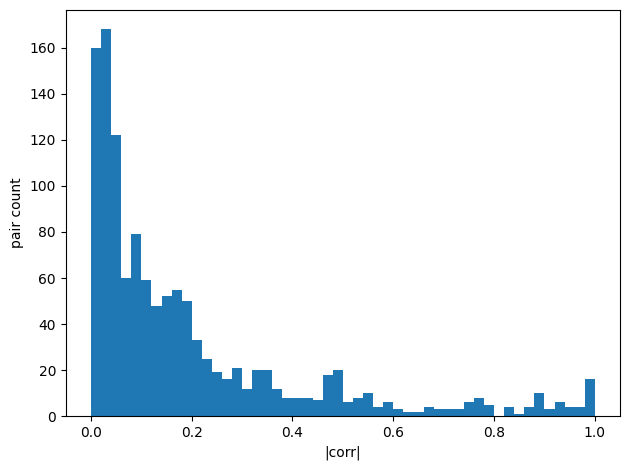

In [5]:
def fit_shiftlog(X_train: pd.DataFrame, skew_ratio_thresh: float):
    mins = np.nanmin(X_train.values, axis=0)
    shift = np.where(mins < 0, -mins, 0.0)

    Xs = X_train.values + shift
    med = np.nanmedian(Xs, axis=0)
    mx = np.nanmax(Xs, axis=0)
    ratio = mx / (med + 1.0)

    log_mask = (ratio > skew_ratio_thresh).astype(bool)
    return {
        "shift": shift,
        "log_mask": log_mask,
        "cols": X_train.columns.tolist(),
        "skew_ratio_thresh": float(skew_ratio_thresh),
    }


def apply_shiftlog(X: pd.DataFrame, params: dict) -> pd.DataFrame:
    cols = params["cols"]
    X = X.reindex(columns=cols)
    arr = X.values.astype(float) + np.array(params["shift"], dtype=float)
    mask = np.array(params["log_mask"], dtype=bool)
    if mask.any():
        arr[:, mask] = np.maximum(arr[:, mask], -0.999999)
        arr[:, mask] = np.log1p(arr[:, mask])
    out = pd.DataFrame(arr, columns=cols, index=X.index)
    return out.replace([np.inf, -np.inf], np.nan)


raw_cols = X_train_raw.columns.tolist()
save_json(paths["logs"] / "train_feature_cols.json", {"train_feature_cols": raw_cols})

X_val_raw = X_val_raw.reindex(columns=raw_cols)
X_test_raw = X_test_raw.reindex(columns=raw_cols)

shiftlog_params = fit_shiftlog(X_train_raw, SKEW_RATIO_THRESH)
joblib.dump(shiftlog_params, paths["preprocess"] / "shiftlog_params.joblib")

X_train_sl = apply_shiftlog(X_train_raw, shiftlog_params)
X_val_sl = apply_shiftlog(X_val_raw, shiftlog_params)
X_test_sl = apply_shiftlog(X_test_raw, shiftlog_params)

imp = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imp.fit_transform(X_train_sl), columns=raw_cols, index=X_train_sl.index)
X_val_imp = pd.DataFrame(imp.transform(X_val_sl), columns=raw_cols, index=X_val_sl.index)
X_test_imp = pd.DataFrame(imp.transform(X_test_sl), columns=raw_cols, index=X_test_sl.index)
joblib.dump(imp, paths["preprocess"] / "imputer_median.joblib")

vt = VarianceThreshold(threshold=VT_THRESHOLD)
X_train_vt_np = vt.fit_transform(X_train_imp.values)
kept_vt = [raw_cols[i] for i in vt.get_support(indices=True)]
X_train_vt = pd.DataFrame(X_train_vt_np, columns=kept_vt, index=X_train_imp.index)
X_val_vt = X_val_imp[kept_vt].copy()
X_test_vt = X_test_imp[kept_vt].copy()

joblib.dump(vt, paths["preprocess"] / "variance_threshold.joblib")
save_json(paths["logs"] / "kept_after_vt.json", {"kept_features": kept_vt})

# Correlation prune (train-only)
corr_df = X_train_vt
if len(corr_df) > 50000:
    corr_df = corr_df.sample(50000, random_state=SEED)

corr = corr_df.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "A", "level_1": "B", 0: "abs_corr"})
    .sort_values("abs_corr", ascending=False)
)
high = pairs[pairs["abs_corr"] > CORR_THRESHOLD].reset_index(drop=True)

# default drop = B, but do not drop protected if the other isn't protected
to_drop = set()
for _, r in high.iterrows():
    a, b = str(r["A"]), str(r["B"])
    a_prot = a in PROTECT_COLS
    b_prot = b in PROTECT_COLS
    if a_prot and not b_prot:
        to_drop.add(b)
    elif b_prot and not a_prot:
        to_drop.add(a)
    elif a_prot and b_prot:
        continue
    else:
        to_drop.add(b)

to_drop = sorted(to_drop)

X_train_corr = X_train_vt.drop(columns=to_drop, errors="ignore")
X_val_corr = X_val_vt.drop(columns=to_drop, errors="ignore")
X_test_corr = X_test_vt.drop(columns=to_drop, errors="ignore")
kept_features = X_train_corr.columns.tolist()

high.to_csv(paths["logs"] / "high_corr_pairs_train.csv", index=False)
save_json(paths["logs"] / "corr_dropped.json", {"threshold": CORR_THRESHOLD, "dropped": to_drop})
save_json(paths["logs"] / "kept_features.json", {"kept_features": kept_features})

plt.figure()
plt.hist(upper.stack().dropna().values, bins=50)
plt.xlabel("|corr|")
plt.ylabel("pair count")
save_fig(paths["plots"] / "corr_hist.png")
plt.show()


Final features: 40


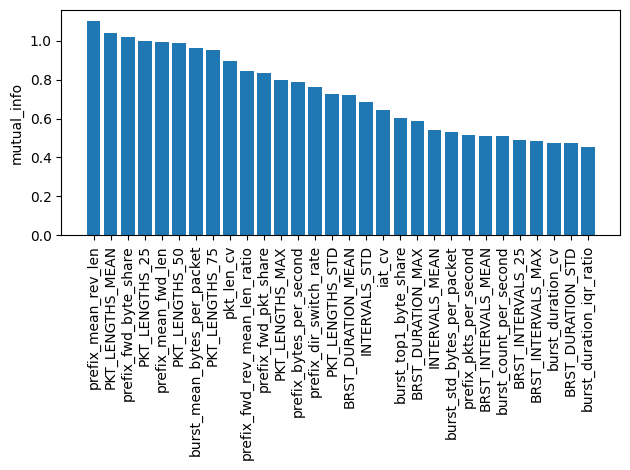

Train class counts: Counter({np.int64(5): 56552, np.int64(0): 14274, np.int64(3): 8787, np.int64(4): 7604, np.int64(2): 7491, np.int64(1): 7261})
Imbalance ratio: 7.788458889960061
SMOTE available: True -> using SMOTE: True
After SMOTE: Counter({np.int64(3): 56552, np.int64(5): 56552, np.int64(2): 56552, np.int64(1): 56552, np.int64(0): 56552, np.int64(4): 56552})


In [6]:
robust = RobustScaler()
std = StandardScaler()

X_train_scaled = std.fit_transform(robust.fit_transform(X_train_corr.values))
X_val_scaled = std.transform(robust.transform(X_val_corr.values))
X_test_scaled = std.transform(robust.transform(X_test_corr.values))

X_train = pd.DataFrame(X_train_scaled, columns=kept_features, index=X_train_corr.index)
X_val = pd.DataFrame(X_val_scaled, columns=kept_features, index=X_val_corr.index)
X_test = pd.DataFrame(X_test_scaled, columns=kept_features, index=X_test_corr.index)

joblib.dump(robust, paths["preprocess"] / "robust_scaler.joblib")
joblib.dump(std, paths["preprocess"] / "standard_scaler.joblib")

print("Final features:", len(kept_features))

# ==========================
# 5) Mutual information rank (optional)
# ==========================
try:
    mi = mutual_info_classif(X_train.values, y_train, random_state=SEED)
    mi_df = pd.DataFrame({"feature": kept_features, "mutual_info": mi}).sort_values("mutual_info", ascending=False)
    mi_df.to_csv(paths["logs"] / "feature_rank_mutual_info.csv", index=False)

    plt.figure()
    top = mi_df.head(30)
    plt.bar(range(len(top)), top["mutual_info"].values)
    plt.xticks(range(len(top)), top["feature"].values, rotation=90)
    plt.ylabel("mutual_info")
    save_fig(paths["plots"] / "mutual_info_top30.png")
    plt.show()
except Exception as e:
    print("Mutual information ranking skipped:", e)

# ================================
# 6) SMOTE (optional, train only)
# ================================
from collections import Counter

IMBLEARN_OK = True
try:
    from imblearn.over_sampling import SMOTE
except Exception:
    IMBLEARN_OK = False

train_counts = Counter(y_train)
imb_ratio = (max(train_counts.values()) / max(1, min(train_counts.values())))
use_smote = bool(AUTO_SMOTE and IMBLEARN_OK and imb_ratio >= 1.5)

print("Train class counts:", train_counts)
print("Imbalance ratio:", float(imb_ratio))
print("SMOTE available:", IMBLEARN_OK, "-> using SMOTE:", use_smote)

X_train_bal = X_train.copy()
y_train_bal = y_train.copy()

if use_smote:
    k = min(SMOTE_K_NEIGHBORS, max(1, min(train_counts.values()) - 1))
    sm = SMOTE(random_state=SEED, k_neighbors=k)
    X_res, y_res = sm.fit_resample(X_train.values, y_train)
    X_train_bal = pd.DataFrame(X_res, columns=kept_features)
    y_train_bal = y_res
    print("After SMOTE:", Counter(y_train_bal))

In [7]:
class Tabular1DDataset(Dataset):
    def __init__(self, X: pd.DataFrame, y: np.ndarray | None = None):
        self.X = torch.from_numpy(np.asarray(X, dtype=np.float32))
        self.y = None if y is None else torch.from_numpy(np.asarray(y, dtype=np.int64))

    def __len__(self) -> int:
        return int(self.X.shape[0])

    def __getitem__(self, i: int):
        xi = self.X[i].unsqueeze(0)  # (1,F)
        return (xi, self.y[i]) if self.y is not None else xi


class FeatureCNN_Attn(nn.Module):
    def __init__(self, n_classes: int, drop: float = 0.35):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 128, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(128)
        self.conv2 = nn.Conv1d(128, 256, 3, padding=1)
        self.bn2 = nn.BatchNorm1d(256)

        self.attn = nn.MultiheadAttention(embed_dim=256, num_heads=4, dropout=drop, batch_first=True)
        self.ln = nn.LayerNorm(256)

        self.emb_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(drop),
        )
        self.out = nn.Linear(128, n_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))  # (B,256,F)
        x = x.transpose(1, 2)  # (B,F,256)

        attn_out, _ = self.attn(x, x, x)
        x = self.ln(x + attn_out)
        x = x.mean(dim=1)  # (B,256)

        emb = self.emb_head(x)  # (B,128)
        logits = self.out(emb)  # (B,C)
        return logits, emb


class FocalLoss(nn.Module):
    def __init__(self, alpha: torch.Tensor | None = None, gamma: float = 1.5):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce = F.cross_entropy(logits, targets, reduction="none", weight=self.alpha)
        with torch.no_grad():
            pt = torch.softmax(logits, dim=1).gather(1, targets.view(-1, 1)).squeeze(1).clamp_min(1e-9)
        loss = ((1.0 - pt) ** self.gamma) * ce
        return loss.mean()


counts = np.bincount(y_train_bal, minlength=len(classes)).astype(np.float32)
w = (1.0 / np.maximum(counts, 1.0))
w = w / w.mean()
class_weights_t = torch.tensor(w, dtype=torch.float32, device=DEVICE)
save_json(paths["logs"] / "class_weights.json", {"class_weights": w.tolist()})

train_loader = DataLoader(Tabular1DDataset(X_train_bal, y_train_bal), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0)
val_loader = DataLoader(Tabular1DDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(Tabular1DDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = FeatureCNN_Attn(n_classes=len(classes), drop=MODEL_DROP).to(DEVICE)
criterion = FocalLoss(alpha=class_weights_t, gamma=FOCAL_GAMMA)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=LR_FACTOR, patience=LR_PATIENCE)

best_val_f1 = -1.0
bad_epochs = 0
best_path = paths["models"] / "cnn_best.pt"

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_macro_f1": [],
    "test_acc": [],
    "test_macro_f1": [],
}


def eval_loader(model: nn.Module, loader: DataLoader):
    model.eval()
    all_preds, all_true, all_logits, all_emb = [], [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            logits, emb = model(xb)
            preds = logits.argmax(dim=1)

            all_preds.append(preds.detach().cpu().numpy())
            all_true.append(yb.detach().cpu().numpy())
            all_logits.append(logits.detach().cpu().numpy())
            all_emb.append(emb.detach().cpu().numpy())

    y_true = np.concatenate(all_true) if len(all_true) else np.array([], dtype=np.int64)
    y_pred = np.concatenate(all_preds) if len(all_preds) else np.array([], dtype=np.int64)
    logits = np.concatenate(all_logits, axis=0) if len(all_logits) else np.zeros((0, len(classes)), dtype=np.float32)
    emb = np.concatenate(all_emb, axis=0) if len(all_emb) else np.zeros((0, 128), dtype=np.float32)

    macro_f1 = float(f1_score(y_true, y_pred, average="macro")) if len(y_true) else float("nan")
    acc = float((y_true == y_pred).mean()) if len(y_true) else float("nan")

    return {"macro_f1": macro_f1, "acc": acc}, y_true, y_pred, logits, emb


for epoch in range(1, int(EPOCHS) + 1):
    model.train()
    running = 0.0
    n = 0
    correct = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits, _ = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += float(loss.item()) * xb.size(0)
        n += xb.size(0)
        correct += int((logits.argmax(dim=1) == yb).sum().item())

    train_loss = running / max(n, 1)
    train_acc = correct / max(n, 1)

    val_metrics, _, _, _, _ = eval_loader(model, val_loader)
    test_metrics, _, _, _, _ = eval_loader(model, test_loader)

    val_f1 = val_metrics["macro_f1"]
    if not np.isnan(val_f1):
        scheduler.step(val_f1)

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_metrics["acc"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["test_acc"].append(test_metrics["acc"])
    history["test_macro_f1"].append(test_metrics["macro_f1"])

    if (not np.isnan(val_f1)) and (val_f1 > best_val_f1):
        best_val_f1 = val_f1
        bad_epochs = 0
        torch.save({"state_dict": model.state_dict(), "best_val_f1": best_val_f1, "epoch": epoch}, best_path)
    else:
        bad_epochs += 1

    print(
        f"Epoch {epoch:03d} | train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
        f"val_acc={val_metrics['acc']:.4f} | val_macro_f1={val_metrics['macro_f1']:.4f} | "
        f"test_acc={test_metrics['acc']:.4f}"
    )

    if bad_epochs >= int(EARLY_STOP_PATIENCE):
        print("Early stopping.")
        break

ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["state_dict"])
print("Loaded best:", str(best_path), "best_val_f1:", ckpt.get("best_val_f1"), "epoch:", ckpt.get("epoch"))

hist_df = pd.DataFrame(history)
hist_df.to_csv(paths["logs"] / "training_history.csv", index=False)
hist_df.to_json(paths["logs"] / "training_history.json", orient="records", indent=2)
display(hist_df.tail(10))


Epoch 001 | train_loss=0.1882 | train_acc=0.8697 | val_acc=0.9246 | val_macro_f1=0.8892 | test_acc=0.9226
Epoch 002 | train_loss=0.1022 | train_acc=0.9217 | val_acc=0.9526 | val_macro_f1=0.9231 | test_acc=0.9519
Epoch 003 | train_loss=0.0856 | train_acc=0.9310 | val_acc=0.9522 | val_macro_f1=0.9241 | test_acc=0.9500
Epoch 004 | train_loss=0.0708 | train_acc=0.9439 | val_acc=0.9546 | val_macro_f1=0.9291 | test_acc=0.9531
Epoch 005 | train_loss=0.0606 | train_acc=0.9520 | val_acc=0.9618 | val_macro_f1=0.9407 | test_acc=0.9587
Epoch 006 | train_loss=0.0557 | train_acc=0.9558 | val_acc=0.9606 | val_macro_f1=0.9395 | test_acc=0.9582
Epoch 007 | train_loss=0.0512 | train_acc=0.9588 | val_acc=0.9655 | val_macro_f1=0.9454 | test_acc=0.9642
Epoch 008 | train_loss=0.0473 | train_acc=0.9620 | val_acc=0.9598 | val_macro_f1=0.9361 | test_acc=0.9560
Epoch 009 | train_loss=0.0450 | train_acc=0.9638 | val_acc=0.9607 | val_macro_f1=0.9401 | test_acc=0.9607
Epoch 010 | train_loss=0.0411 | train_acc=0.96

,epoch,train_loss,train_acc,val_acc,val_macro_f1,test_acc,test_macro_f1
25,26,0.019684,0.983033,0.969314,0.953680,0.969830,0.954945
26,27,0.014790,0.986691,0.970481,0.956193,0.971821,0.958924
27,28,0.014250,0.987021,0.971580,0.958231,0.972027,0.959115
28,29,0.014010,0.987106,0.973433,0.959437,0.974704,0.961871
29,30,0.013450,0.987808,0.972472,0.958130,0.973915,0.960540
30,31,0.013389,0.987743,0.973364,0.958935,0.973880,0.960548
31,32,0.012931,0.988250,0.970893,0.956776,0.970688,0.956269
32,33,0.012741,0.988223,0.970756,0.956600,0.972610,0.959555
33,34,0.010845,0.990000,0.973296,0.959740,0.974704,0.962281
34,35,0.010391,0.990218,0.974120,0.960610,0.975699,0.963320


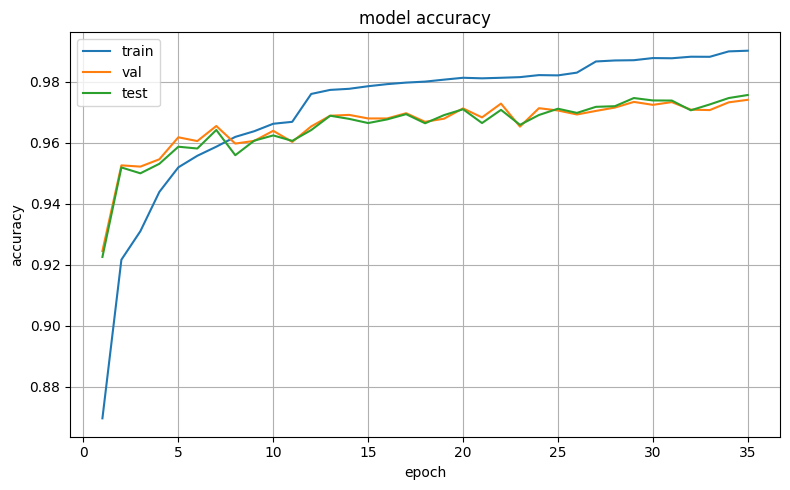

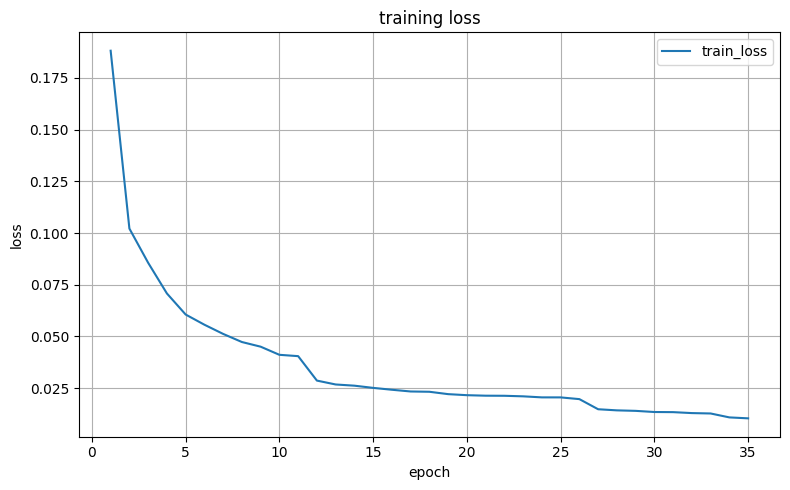

In [8]:
hist = pd.read_csv(paths["logs"] / "training_history.csv")

plt.figure(figsize=(8, 5))
plt.plot(hist["epoch"], hist["train_acc"], label="train")
plt.plot(hist["epoch"], hist["val_acc"], label="val")
plt.plot(hist["epoch"], hist["test_acc"], label="test")
plt.title("model accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(paths["plots"] / "model_accuracy_curve.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(hist["epoch"], hist["train_loss"], label="train_loss")
plt.title("training loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(paths["plots"] / "train_loss_curve.png", dpi=200)
plt.show()


TEST metrics: {'macro_f1': 0.9633195135854495, 'acc': 0.975699330701905}
              precision    recall  f1-score   support

           D     0.9536    0.9573    0.9555      4079
           L     0.9721    0.9749    0.9735      2075
           M     0.8777    0.9421    0.9087      2140
           P     0.9698    0.9725    0.9712      2511
           U     0.9833    0.9779    0.9806      2172
           W     0.9958    0.9851    0.9904     16158

    accuracy                         0.9757     29135
   macro avg     0.9587    0.9683    0.9633     29135
weighted avg     0.9764    0.9757    0.9759     29135



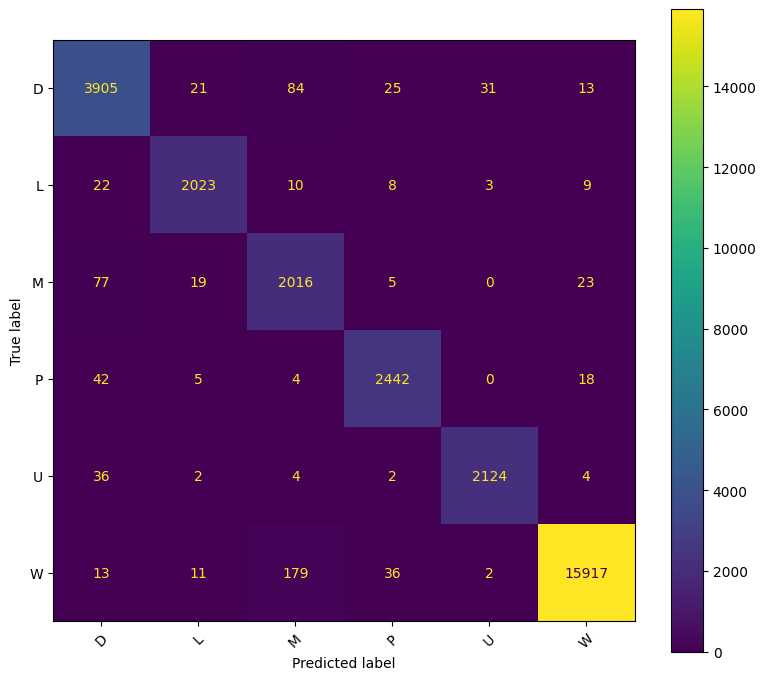

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_metrics, yt_true, yt_pred, test_logits_tmp, test_emb_tmp = eval_loader(model, test_loader)
print("TEST metrics:", test_metrics)
print(classification_report(yt_true, yt_pred, target_names=le.classes_.tolist(), digits=4))

rep_dict = classification_report(
    yt_true, yt_pred,
    target_names=le.classes_.tolist(),
    digits=4,
    output_dict=True
)
save_json(paths["logs"] / "classification_report_test.json", rep_dict)

cm = confusion_matrix(yt_true, yt_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=le.classes_.tolist()).plot(ax=ax, xticks_rotation=45)
plt.tight_layout()
plt.savefig(paths["plots"] / "test_confusion_matrix.png", dpi=200)
plt.show()


# ==========================================================
# 10) Temperature scaling + calibration metrics + routing-based selection
#     Main idea (same as ISCX notebook):
#       - Fit temperature scaler on VAL logits
#       - Compare routing utility (VAL) for RAW vs CAL probs
#       - Use CAL only if it improves VAL routing utility
# ==========================================================
def softmax_np(logits: np.ndarray) -> np.ndarray:
    z = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(z)
    return exp / exp.sum(axis=1, keepdims=True)


@torch.no_grad()
def collect_logits_emb(model: nn.Module, loader: DataLoader):
    model.eval()
    L, Y, E = [], [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        logits, emb = model(xb)
        L.append(logits.detach().cpu().numpy())
        E.append(emb.detach().cpu().numpy())
        Y.append(yb.detach().cpu().numpy())
    return np.concatenate(L, axis=0), np.concatenate(Y, axis=0), np.concatenate(E, axis=0)


def ece_score(probs: np.ndarray, y_true: np.ndarray, bins: int = 15) -> float:
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for i in range(bins):
        lo, hi = edges[i], edges[i + 1]
        m = (conf >= lo) & (conf < hi)
        if m.sum() == 0:
            continue
        ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def nll_score(probs: np.ndarray, y_true: np.ndarray) -> float:
    p = np.clip(probs[np.arange(len(y_true)), y_true], 1e-12, 1.0)
    return float(-np.mean(np.log(p)))


def brier_score(probs: np.ndarray, y_true: np.ndarray, n_classes: int) -> float:
    y_onehot = np.zeros((len(y_true), n_classes), dtype=np.float32)
    y_onehot[np.arange(len(y_true)), y_true] = 1.0
    return float(np.mean(np.sum((probs - y_onehot) ** 2, axis=1)))


def reliability_curve_data(probs: np.ndarray, y_true: np.ndarray, bins: int = 15):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    centers = (edges[:-1] + edges[1:]) / 2.0

    accs, confs, counts = [], [], []
    for i in range(bins):
        lo, hi = edges[i], edges[i + 1]
        m = (conf >= lo) & (conf < hi)
        if m.sum() == 0:
            accs.append(np.nan);
            confs.append(np.nan);
            counts.append(0)
        else:
            accs.append(float(correct[m].mean()))
            confs.append(float(conf[m].mean()))
            counts.append(int(m.sum()))
    return centers, np.array(accs), np.array(confs), np.array(counts)


def plot_reliability(probs: np.ndarray, y_true: np.ndarray, title: str, bins: int = 15):
    centers, accs, _, _ = reliability_curve_data(probs, y_true, bins=bins)
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1])
    plt.plot(centers, accs, marker="o")
    plt.xlabel("confidence")
    plt.ylabel("accuracy")
    plt.title(title)
    plt.grid(True)

In [10]:
class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(1))

    def forward(self, logits: torch.Tensor) -> torch.Tensor:
        t = torch.exp(self.log_t).clamp(1e-3, 1e3)
        return logits / t

    def temperature(self) -> float:
        return float(torch.exp(self.log_t).detach().cpu().item())

    def fit(self, logits: np.ndarray, y_true: np.ndarray, max_iter: int = 50) -> float:
        self.to(DEVICE)
        x = torch.tensor(logits, dtype=torch.float32, device=DEVICE)
        y = torch.tensor(y_true, dtype=torch.long, device=DEVICE)
        opt = torch.optim.LBFGS([self.log_t], lr=0.1, max_iter=max_iter)

        def closure():
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(self.forward(x), y)
            loss.backward()
            return loss

        opt.step(closure)
        return self.temperature()


def routing_sweep(probs: np.ndarray, y_true: np.ndarray, thresholds: Optional[np.ndarray] = None) -> pd.DataFrame:
    if thresholds is None:
        thresholds = np.linspace(0.0, 1.0, 101)
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    rows = []
    for t in thresholds:
        accept = conf >= t
        coverage = float(accept.mean())
        if accept.sum() == 0:
            rows.append({"threshold": float(t), "coverage": coverage, "macro_f1": float("nan")})
        else:
            rows.append({
                "threshold": float(t),
                "coverage": coverage,
                "macro_f1": float(f1_score(y_true[accept], pred[accept], average="macro")),
            })
    return pd.DataFrame(rows)


def pick_tau(grid: pd.DataFrame) -> float:
    eligible = grid.dropna().sort_values(["macro_f1", "coverage"], ascending=[False, False])
    return float(eligible.iloc[0]["threshold"]) if len(eligible) else 0.0


def evaluate_policy(y_true: np.ndarray, y_pred: np.ndarray, actions: np.ndarray, beta: float,
                    route_cost: float) -> dict:
    actions = np.asarray(actions, dtype=int)
    accept = actions == 0
    routed = ~accept

    coverage = float(accept.mean()) if len(actions) else 0.0
    if accept.sum() == 0:
        macro_f1 = float("nan")
        acc = float("nan")
        wrong_accept = 0
        correct_accept = 0
    else:
        macro_f1 = float(f1_score(y_true[accept], y_pred[accept], average="macro"))
        acc = float(accuracy_score(y_true[accept], y_pred[accept]))
        correct_accept = int((y_true[accept] == y_pred[accept]).sum())
        wrong_accept = int((y_true[accept] != y_pred[accept]).sum())

    total = len(actions)
    utility = (correct_accept - float(beta) * wrong_accept - float(route_cost) * int(routed.sum())) / max(1, total)

    return {
        "coverage": float(coverage),
        "macro_f1_accept": float(macro_f1),
        "acc_accept": float(acc),
        "routed": int(routed.sum()),
        "accepted": int(accept.sum()),
        "utility": float(utility),
        "wrong_accept": int(wrong_accept),
        "correct_accept": int(correct_accept),
    }


Temperature T: 1.387916922569275
VAL  | ECE: 0.006252591133837828 -> 0.005845623154413365 | NLL: 0.0814233347773552 -> 0.07597515732049942 | Brier: 0.036560431122779846 -> 0.036488126963377
TEST | ECE: 0.005388904433113729 -> 0.00502177920107455 | NLL: 0.076334647834301 -> 0.07250058650970459 | Brier: 0.03610021993517876 -> 0.0361885204911232


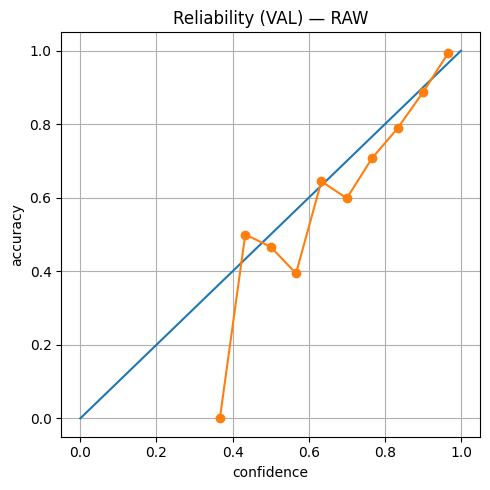

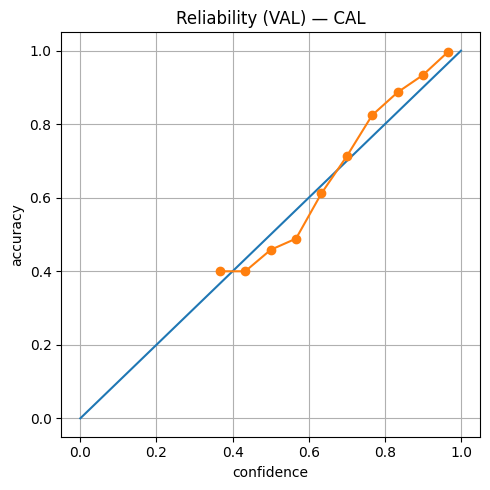

In [11]:
# ---- logits/embeddings ----
val_logits, val_y_np, _ = collect_logits_emb(model, val_loader)
test_logits, test_y_np, test_emb = collect_logits_emb(model, test_loader)

# ---- fit temperature scaler on VAL ----
temp = TemperatureScaler()
T = temp.fit(val_logits, val_y_np)

# ---- probs ----
val_probs_raw = softmax_np(val_logits)
test_probs_raw = softmax_np(test_logits)

val_logits_cal = temp(torch.tensor(val_logits, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()
test_logits_cal = temp(torch.tensor(test_logits, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()

val_probs_cal = softmax_np(val_logits_cal)
test_probs_cal = softmax_np(test_logits_cal)

# ---- calibration metrics ----
n_classes = int(val_probs_raw.shape[1])
calib_metrics = {
    "T": float(T),
    "val": {
        "ece_raw": ece_score(val_probs_raw, val_y_np),
        "ece_cal": ece_score(val_probs_cal, val_y_np),
        "nll_raw": nll_score(val_probs_raw, val_y_np),
        "nll_cal": nll_score(val_probs_cal, val_y_np),
        "brier_raw": brier_score(val_probs_raw, val_y_np, n_classes),
        "brier_cal": brier_score(val_probs_cal, val_y_np, n_classes),
    },
    "test": {
        "ece_raw": ece_score(test_probs_raw, test_y_np),
        "ece_cal": ece_score(test_probs_cal, test_y_np),
        "nll_raw": nll_score(test_probs_raw, test_y_np),
        "nll_cal": nll_score(test_probs_cal, test_y_np),
        "brier_raw": brier_score(test_probs_raw, test_y_np, n_classes),
        "brier_cal": brier_score(test_probs_cal, test_y_np, n_classes),
    },
}
save_json(paths["logs"] / "temperature_scaling_metrics.json", calib_metrics)
torch.save({"state_dict": temp.state_dict(), "T": float(T)}, paths["models"] / "temperature_scaler.pt")

print("Temperature T:", float(T))
print("VAL  | ECE:", calib_metrics["val"]["ece_raw"], "->", calib_metrics["val"]["ece_cal"],
      "| NLL:", calib_metrics["val"]["nll_raw"], "->", calib_metrics["val"]["nll_cal"],
      "| Brier:", calib_metrics["val"]["brier_raw"], "->", calib_metrics["val"]["brier_cal"])
print("TEST | ECE:", calib_metrics["test"]["ece_raw"], "->", calib_metrics["test"]["ece_cal"],
      "| NLL:", calib_metrics["test"]["nll_raw"], "->", calib_metrics["test"]["nll_cal"],
      "| Brier:", calib_metrics["test"]["brier_raw"], "->", calib_metrics["test"]["brier_cal"])

plot_reliability(val_probs_raw, val_y_np, "Reliability (VAL) — RAW")
save_fig(paths["plots"] / "reliability_val_raw.png")
plt.show()

plot_reliability(val_probs_cal, val_y_np, "Reliability (VAL) — CAL")
save_fig(paths["plots"] / "reliability_val_cal.png")
plt.show()


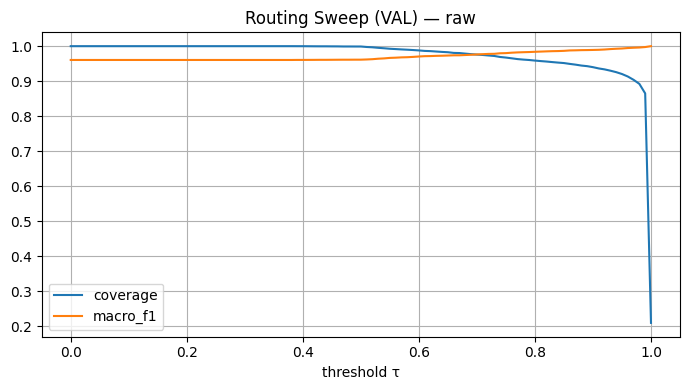

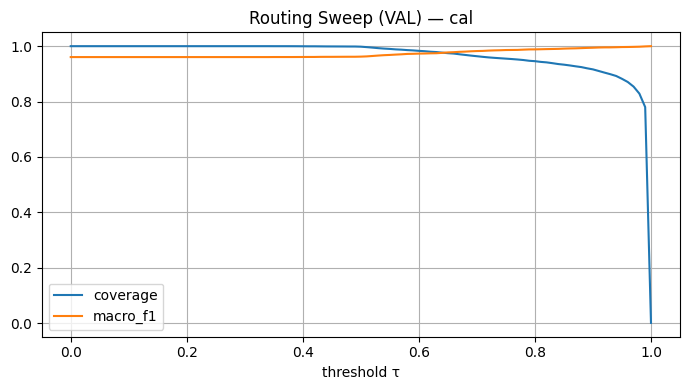

Routing selection: {'use_temperature_for_routing': False, 'selected': 'raw', 'criterion': 'val_utility_threshold_routing', 'raw_val_utility': 0.2023724857554747, 'cal_val_utility': -0.01363910533850429}


In [12]:
def compare_threshold_routing(val_probs: np.ndarray, test_probs: np.ndarray, tag: str) -> dict:
    grid_val = routing_sweep(val_probs, val_y_np)
    tau = pick_tau(grid_val)

    mean_conf = float(val_probs.max(axis=1).mean())
    beta = float(max(1.0, np.log(len(classes) + 1)))
    route_cost = float(max(0.01, min(0.25, 0.5 * (1.0 - mean_conf))))

    val_conf = val_probs.max(axis=1)
    val_pred = val_probs.argmax(axis=1)
    val_actions = np.where(val_conf >= tau, 0, 1)
    val_metrics = evaluate_policy(val_y_np, val_pred, val_actions, beta, route_cost)

    test_conf = test_probs.max(axis=1)
    test_pred = test_probs.argmax(axis=1)
    test_actions = np.where(test_conf >= tau, 0, 1)
    test_metrics = evaluate_policy(test_y_np, test_pred, test_actions, beta, route_cost)

    grid_val.to_csv(paths["logs"] / f"routing_sweep_val_{tag}.csv", index=False)

    plt.figure(figsize=(7, 4))
    plt.plot(grid_val["threshold"], grid_val["coverage"], label="coverage")
    plt.plot(grid_val["threshold"], grid_val["macro_f1"], label="macro_f1")
    plt.xlabel("threshold τ")
    plt.title(f"Routing Sweep (VAL) — {tag}")
    plt.legend()
    plt.grid(True)
    save_fig(paths["plots"] / f"routing_sweep_val_{tag}.png")
    plt.show()

    return {
        "tag": tag,
        "tau": float(tau),
        "beta": float(beta),
        "route_cost": float(route_cost),
        "val_metrics": val_metrics,
        "test_metrics": test_metrics,
    }


raw_routing = compare_threshold_routing(val_probs_raw, test_probs_raw, "raw")
cal_routing = compare_threshold_routing(val_probs_cal, test_probs_cal, "cal")

routing_compare = {"raw": raw_routing, "cal": cal_routing}
save_json(paths["logs"] / "routing_compare_threshold.json", routing_compare)

USE_TEMPERATURE_FOR_ROUTING = bool(cal_routing["val_metrics"]["utility"] > raw_routing["val_metrics"]["utility"])
choice = {
    "use_temperature_for_routing": USE_TEMPERATURE_FOR_ROUTING,
    "selected": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
    "criterion": "val_utility_threshold_routing",
    "raw_val_utility": float(raw_routing["val_metrics"]["utility"]),
    "cal_val_utility": float(cal_routing["val_metrics"]["utility"]),
}
save_json(paths["logs"] / "routing_choice.json", choice)

print("Routing selection:", choice)

In [13]:
def probs_to_state(probs: np.ndarray) -> np.ndarray:
    probs = np.asarray(probs, dtype=np.float32)
    conf = probs.max(axis=1, keepdims=True)
    top2 = np.partition(probs, -2, axis=1)[:, -2:]
    margin = (top2[:, 1] - top2[:, 0]).reshape(-1, 1).astype(np.float32)
    entropy = (-np.sum(probs * np.log(np.clip(probs, 1e-9, 1.0)), axis=1, keepdims=True)).astype(np.float32)
    return np.concatenate([probs, conf.astype(np.float32), entropy, margin], axis=1).astype(np.float32)


@torch.no_grad()
def probs_from_logits_selected(logits_np: np.ndarray) -> np.ndarray:
    if USE_TEMPERATURE_FOR_ROUTING:
        logits_np = temp(torch.tensor(logits_np, dtype=torch.float32, device=DEVICE)).detach().cpu().numpy()
    return softmax_np(logits_np)


# Train logits from the original (pre-SMOTE) train split
train_raw_loader = DataLoader(Tabular1DDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
train_logits, train_y_np, _ = collect_logits_emb(model, train_raw_loader)

train_probs_sel = probs_from_logits_selected(train_logits)
val_probs_sel = probs_from_logits_selected(val_logits)
test_probs_sel = probs_from_logits_selected(test_logits)

train_state = probs_to_state(train_probs_sel)
val_state = probs_to_state(val_probs_sel)
test_state = probs_to_state(test_probs_sel)

train_pred = train_probs_sel.argmax(axis=1)
val_pred = val_probs_sel.argmax(axis=1)
test_pred = test_probs_sel.argmax(axis=1)

print("RL state dim:", int(train_state.shape[1]))

np.savez_compressed(
    paths["cache"] / "routing_selected_arrays.npz",
    use_temperature_for_routing=np.array([int(USE_TEMPERATURE_FOR_ROUTING)]),
    train_logits=train_logits, val_logits=val_logits, test_logits=test_logits,
    train_probs=train_probs_sel, val_probs=val_probs_sel, test_probs=test_probs_sel,
    train_y=train_y_np, val_y=val_y_np, test_y=test_y_np,
    test_emb=test_emb,
)



RL state dim: 9


In [14]:
def set_seed(seed: int) -> None:
    seed = int(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class RLDecisionLayer(nn.Module):
    def __init__(self, in_dim: int, hidden: int = 64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, 2))

    def forward(self, s: torch.Tensor) -> torch.Tensor:
        return self.net(s)


class ReplayBuffer:
    def __init__(self, capacity: int, state_dim: int):
        self.capacity = int(capacity)
        self.state = np.zeros((capacity, state_dim), dtype=np.float32)
        self.action = np.zeros((capacity,), dtype=np.int64)
        self.reward = np.zeros((capacity,), dtype=np.float32)
        self.ptr = 0
        self.size = 0

    def add(self, s: np.ndarray, a: int, r: float) -> None:
        i = self.ptr
        self.state[i] = s
        self.action[i] = int(a)
        self.reward[i] = float(r)
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int):
        idx = np.random.randint(0, self.size, size=batch_size)
        return self.state[idx], self.action[idx], self.reward[idx]


def compute_reward(action: int, is_correct: bool, beta: float, route_cost: float) -> float:
    if action == 0:
        return 1.0 if is_correct else -float(beta)
    return -float(route_cost)


@torch.no_grad()
def policy_actions(policy: nn.Module, states: np.ndarray, batch: int = 4096) -> np.ndarray:
    policy.eval()
    out = []
    for i in range(0, len(states), batch):
        s = torch.tensor(states[i:i + batch], dtype=torch.float32, device=DEVICE)
        q = policy(s)
        out.append(q.argmax(dim=1).detach().cpu().numpy())
    return np.concatenate(out, axis=0) if out else np.array([], dtype=int)


def train_dqn_bandit(
        train_states: np.ndarray,
        train_y: np.ndarray,
        train_pred: np.ndarray,
        val_states: np.ndarray,
        val_y: np.ndarray,
        val_pred: np.ndarray,
        beta: float,
        route_cost: float,
        seed: int,
        hidden: int = 64,
        steps: int = 9000,
        batch_size: int = 512,
        buffer_size: int = 50000,
        warmup: int = 1500,
        lr: float = 1e-3,
        eps_start: float = 1.0,
        eps_end: float = 0.05,
        eps_decay: float = 0.9995,
):
    set_seed(seed)
    state_dim = train_states.shape[1]
    policy = RLDecisionLayer(state_dim, hidden=hidden).to(DEVICE)
    opt = torch.optim.AdamW(policy.parameters(), lr=lr, weight_decay=1e-4)
    buf = ReplayBuffer(buffer_size, state_dim)

    eps = eps_start
    best_val_util = -1e18
    best_state = None

    n = len(train_states)
    for t in range(1, steps + 1):
        i = np.random.randint(0, n)
        s = train_states[i]
        correct = bool(train_pred[i] == train_y[i])

        if np.random.rand() < eps:
            a = np.random.randint(0, 2)
        else:
            with torch.no_grad():
                q = policy(torch.tensor(s, dtype=torch.float32, device=DEVICE).unsqueeze(0))
                a = int(q.argmax(dim=1).item())

        r = compute_reward(a, correct, beta, route_cost)
        buf.add(s, a, r)
        eps = max(eps_end, eps * eps_decay)

        if buf.size >= warmup:
            s_b, a_b, r_b = buf.sample(batch_size)
            s_t = torch.tensor(s_b, dtype=torch.float32, device=DEVICE)
            a_t = torch.tensor(a_b, dtype=torch.int64, device=DEVICE).unsqueeze(1)
            r_t = torch.tensor(r_b, dtype=torch.float32, device=DEVICE).unsqueeze(1)

            q = policy(s_t).gather(1, a_t)
            loss = F.smooth_l1_loss(q, r_t)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(policy.parameters(), 2.0)
            opt.step()

        if t % 1500 == 0:
            act_val = policy_actions(policy, val_states)
            val_m = evaluate_policy(val_y, val_pred, act_val, beta, route_cost)
            if val_m["utility"] > best_val_util:
                best_val_util = val_m["utility"]
                best_state = {k: v.detach().cpu().clone() for k, v in policy.state_dict().items()}
            print(
                f"step={t} eps={eps:.3f} val_utility={val_m['utility']:.4f} coverage={val_m['coverage']:.3f} macro_f1={val_m['macro_f1_accept']:.4f}"
            )

    if best_state is not None:
        policy.load_state_dict(best_state)
    return policy


mean_conf = float(val_probs_sel.max(axis=1).mean())
base_beta = float(max(1.0, np.log(len(classes) + 1)))
beta_grid = [base_beta * k for k in [1.0, 2.0, 3.0, 4.0]]

c_base = float(max(0.01, min(0.25, 0.5 * (1.0 - mean_conf))))
route_cost_grid = [c_base * k for k in [0.5, 1.0, 2.0, 4.0]]

best = None
best_policy = None

for beta in beta_grid:
    for c in route_cost_grid:
        pol = train_dqn_bandit(
            train_state, train_y_np, train_pred,
            val_state, val_y_np, val_pred,
            beta=float(beta),
            route_cost=float(c),
            seed=SEED
        )
        val_actions = policy_actions(pol, val_state)
        val_metrics = evaluate_policy(val_y_np, val_pred, val_actions, float(beta), float(c))
        cand = {"beta": float(beta), "route_cost": float(c), "val": val_metrics}
        if (best is None) or (cand["val"]["utility"] > best["val"]["utility"]):
            best = cand
            best_policy = pol

print("Selected RL params:", best)

test_actions = policy_actions(best_policy, test_state)
test_metrics_rl = evaluate_policy(test_y_np, test_pred, test_actions, best["beta"], best["route_cost"])
print("Test RL metrics:", test_metrics_rl)

save_json(paths["logs"] / "rl_selected.json", best)
save_json(paths["logs"] / "rl_test_metrics.json", test_metrics_rl)

torch.save(
    {
        "state_dict": best_policy.state_dict(),
        "state_dim": int(train_state.shape[1]),
        "hidden": 64,
        "beta": float(best["beta"]),
        "route_cost": float(best["route_cost"]),
        "use_temperature_for_routing": bool(USE_TEMPERATURE_FOR_ROUTING),
        "selected_probs_variant": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
    },
    paths["models"] / "rl_policy.pt"
)

np.save(paths["cache"] / "test_actions_rl.npy", test_actions)

step=1500 eps=0.472 val_utility=0.2498 coverage=0.264 macro_f1=0.4945
step=3000 eps=0.223 val_utility=0.9238 coverage=1.000 macro_f1=0.9606
step=4500 eps=0.105 val_utility=0.9255 coverage=0.998 macro_f1=0.9622
step=6000 eps=0.050 val_utility=0.9274 coverage=0.996 macro_f1=0.9636
step=7500 eps=0.050 val_utility=0.9278 coverage=0.996 macro_f1=0.9642
step=9000 eps=0.050 val_utility=0.9286 coverage=0.994 macro_f1=0.9655
step=1500 eps=0.472 val_utility=0.2461 coverage=0.264 macro_f1=0.4945
step=3000 eps=0.223 val_utility=0.9238 coverage=1.000 macro_f1=0.9606
step=4500 eps=0.105 val_utility=0.9254 coverage=0.998 macro_f1=0.9621
step=6000 eps=0.050 val_utility=0.9276 coverage=0.996 macro_f1=0.9639
step=7500 eps=0.050 val_utility=0.9277 coverage=0.996 macro_f1=0.9642
step=9000 eps=0.050 val_utility=0.9278 coverage=0.994 macro_f1=0.9650
step=1500 eps=0.472 val_utility=0.2387 coverage=0.264 macro_f1=0.4945
step=3000 eps=0.223 val_utility=0.9238 coverage=1.000 macro_f1=0.9606
step=4500 eps=0.105 

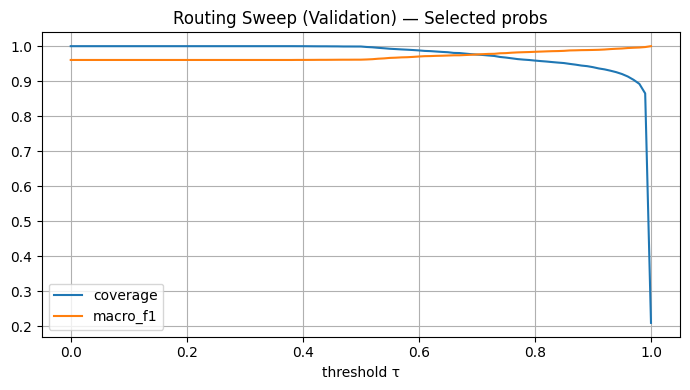

Chosen τ: 1.0
Threshold test metrics: {'coverage': 0.20830616097477261, 'macro_f1_accept': 1.0, 'acc_accept': 1.0, 'routed': 23066, 'accepted': 6069, 'utility': 0.20434769177964648, 'wrong_accept': 0, 'correct_accept': 6069}


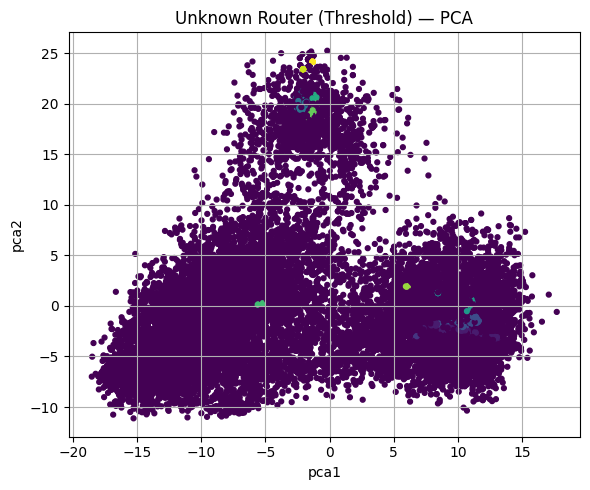

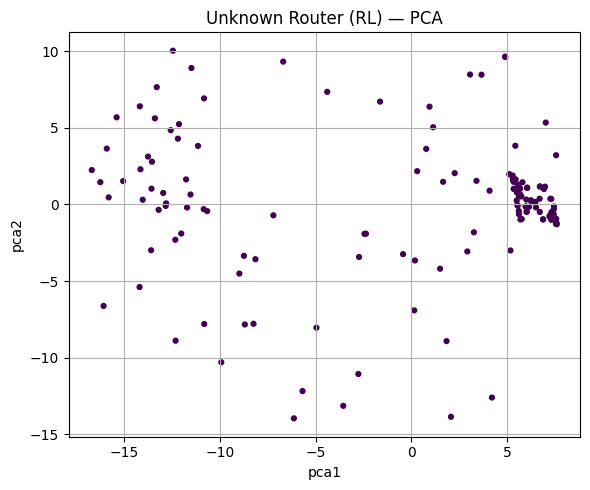

Unknown(threshold): {'tau': 1.0, 'routed_count': 23066, 'dbscan_eps': 0.7, 'dbscan_min_samples': 20, 'clusters': [{'cluster_id': -1, 'count': 20347}, {'cluster_id': 0, 'count': 1173}, {'cluster_id': 1, 'count': 21}, {'cluster_id': 2, 'count': 953}, {'cluster_id': 3, 'count': 24}, {'cluster_id': 4, 'count': 136}, {'cluster_id': 5, 'count': 110}, {'cluster_id': 6, 'count': 36}, {'cluster_id': 7, 'count': 76}, {'cluster_id': 8, 'count': 47}, {'cluster_id': 9, 'count': 57}, {'cluster_id': 10, 'count': 37}, {'cluster_id': 11, 'count': 24}, {'cluster_id': 12, 'count': 25}]}
Unknown(RL): {'beta': 1.9459101490553132, 'route_cost': 0.005, 'routed_count': 162, 'dbscan_eps': 0.7, 'dbscan_min_samples': 20, 'clusters': [{'cluster_id': -1, 'count': 162}]}


In [15]:
grid = routing_sweep(val_probs_sel, val_y_np)
grid.to_csv(paths["logs"] / "routing_sweep_val_selected.csv", index=False)

plt.figure(figsize=(7, 4))
plt.plot(grid["threshold"], grid["coverage"], label="coverage")
plt.plot(grid["threshold"], grid["macro_f1"], label="macro_f1")
plt.xlabel("threshold τ")
plt.title("Routing Sweep (Validation) — Selected probs")
plt.legend()
plt.grid(True)
save_fig(paths["plots"] / "routing_sweep_val_selected.png")
plt.show()

eligible = grid.dropna().sort_values(["macro_f1", "coverage"], ascending=[False, False])
tau = float(eligible.iloc[0]["threshold"]) if len(eligible) else 0.0
print("Chosen τ:", tau)

conf_test = test_probs_sel.max(axis=1)
actions_thr = np.where(conf_test >= tau, 0, 1)

thr_metrics = evaluate_policy(test_y_np, test_pred, actions_thr, float(best["beta"]), float(best["route_cost"]))
print("Threshold test metrics:", thr_metrics)

save_json(paths["logs"] / "routing_tau.json", {"tau": float(tau)})
save_json(paths["logs"] / "threshold_test_metrics.json", thr_metrics)
np.save(paths["cache"] / "test_actions_threshold.npy", actions_thr)

# ==========================================================
# 14) Unknown Router (DBSCAN + PCA) + save summaries/plots
# ==========================================================
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


def cluster_unknowns(embeddings: np.ndarray, eps: float, min_samples: int) -> np.ndarray:
    if embeddings is None or len(embeddings) == 0:
        return np.array([], dtype=int)
    Z = StandardScaler().fit_transform(embeddings)
    return DBSCAN(eps=float(eps), min_samples=int(min_samples), metric="euclidean").fit_predict(Z)


def pca_plot_save(embeddings: np.ndarray, labels: np.ndarray, title: str, save_path: Path) -> None:
    if embeddings is None or len(embeddings) == 0:
        print(f"{title}: no embeddings to plot.")
        return
    xy = PCA(n_components=2, random_state=SEED).fit_transform(embeddings)
    plt.figure(figsize=(6, 5))
    plt.scatter(xy[:, 0], xy[:, 1], c=labels, s=12)
    plt.xlabel("pca1")
    plt.ylabel("pca2")
    plt.title(title)
    plt.grid(True)
    save_fig(save_path)
    plt.show()


def _cluster_summary(labels: np.ndarray) -> list[dict]:
    if labels is None or labels.size == 0:
        return []
    vc = pd.Series(labels).value_counts(dropna=False).sort_index()
    return [{"cluster_id": int(i), "count": int(c)} for i, c in vc.items()]


routed_thr = (actions_thr == 1)
emb_thr = test_emb[routed_thr]
labels_thr = cluster_unknowns(emb_thr, DBSCAN_EPS, DBSCAN_MIN_SAMPLES)
pca_plot_save(emb_thr, labels_thr, "Unknown Router (Threshold) — PCA",
              paths["plots"] / "unknown_router_threshold_pca.png")

unknown_thr = {
    "tau": float(tau),
    "routed_count": int(routed_thr.sum()),
    "dbscan_eps": float(DBSCAN_EPS),
    "dbscan_min_samples": int(DBSCAN_MIN_SAMPLES),
    "clusters": _cluster_summary(labels_thr),
}

routed_rl = (test_actions == 1)
emb_rl = test_emb[routed_rl]
labels_rl = cluster_unknowns(emb_rl, DBSCAN_EPS, DBSCAN_MIN_SAMPLES)
pca_plot_save(emb_rl, labels_rl, "Unknown Router (RL) — PCA", paths["plots"] / "unknown_router_rl_pca.png")

unknown_rl = {
    "beta": float(best["beta"]),
    "route_cost": float(best["route_cost"]),
    "routed_count": int(routed_rl.sum()),
    "dbscan_eps": float(DBSCAN_EPS),
    "dbscan_min_samples": int(DBSCAN_MIN_SAMPLES),
    "clusters": _cluster_summary(labels_rl),
}

save_json(paths["logs"] / "unknown_router_threshold.json", unknown_thr)
save_json(paths["logs"] / "unknown_router_rl.json", unknown_rl)

print("Unknown(threshold):", unknown_thr)
print("Unknown(RL):", unknown_rl)


In [16]:
joblib.dump(le, paths["preprocess"] / "label_encoder.joblib")

run_card = {
    "run_name": str(RUN_NAME),
    "dataset_name": str(DATASET_NAME),
    "created_at": datetime.utcnow().isoformat() + "Z",
    "device": str(DEVICE),
    "n_classes": int(len(classes)),
    "final_feature_count": int(len(kept_features)),
    "temperature_T": float(T),
    "use_temperature_for_routing": bool(USE_TEMPERATURE_FOR_ROUTING),
    "selected_probs_variant": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
    "tau_selected_probs": float(tau),
}
save_json(paths["logs"] / "run_card.json", run_card)

bundle_dir = paths["root"] / "bundle"
reset_dir(bundle_dir)

bundle_paths = {
    "root": bundle_dir,
    "models": bundle_dir / "models",
    "preprocess": bundle_dir / "preprocess",
    "logs": bundle_dir / "logs",
}
for p in bundle_paths.values():
    if isinstance(p, Path):
        p.mkdir(parents=True, exist_ok=True)

# Minimal inference bundle only: models + preprocess artifacts + essential metadata.
for model_name in ["cnn_best.pt", "temperature_scaler.pt", "rl_policy.pt"]:
    safe_copy(paths["models"] / model_name, bundle_paths["models"] / model_name)

for prep_name in [
    "label_encoder.joblib",
    "shiftlog_params.joblib",
    "imputer_median.joblib",
    "variance_threshold.joblib",
    "robust_scaler.joblib",
    "standard_scaler.joblib",
]:
    safe_copy(paths["preprocess"] / prep_name, bundle_paths["preprocess"] / prep_name)

for log_name in [
    "config.json",
    "classes.json",
    "kept_features.json",
    "run_card.json",
    "routing_choice.json",
    "routing_tau.json",
    "temperature_scaling_metrics.json",
    "rl_selected.json",
]:
    safe_copy(paths["logs"] / log_name, bundle_paths["logs"] / log_name)

inference_bundle = {
    "bundle_root": str(bundle_dir),
    "models_dir": "models",
    "preprocess_dir": "preprocess",
    "logs_dir": "logs",
    "model_file": "cnn_best.pt",
    "temperature_scaler_file": "temperature_scaler.pt",
    "rl_policy_file": "rl_policy.pt",
    "label_encoder_file": "label_encoder.joblib",
    "shiftlog_params_file": "shiftlog_params.joblib",
    "imputer_file": "imputer_median.joblib",
    "variance_threshold_file": "variance_threshold.joblib",
    "robust_scaler_file": "robust_scaler.joblib",
    "standard_scaler_file": "standard_scaler.joblib",
    "kept_features_file": "kept_features.json",
    "classes_file": "classes.json",
    "config_file": "config.json",
    "run_card_file": "run_card.json",
    "use_temperature_for_routing": bool(USE_TEMPERATURE_FOR_ROUTING),
    "selected_probs_variant": "cal" if USE_TEMPERATURE_FOR_ROUTING else "raw",
}
save_json(bundle_dir / "inference_bundle.json", inference_bundle)

zip_path = shutil.make_archive(str(bundle_dir), "zip", root_dir=bundle_dir)
print("Minimal bundle created:", zip_path)
print("Everything saved under:", paths["root"])


Minimal bundle created: D:\FYP_ML_FINAL\HTTPS_stat\v8\https_ratio_v1\bundle.zip
Everything saved under: v8\https_ratio_v1


C:\Users\user\AppData\Local\Temp\ipykernel_28076\3310660561.py:6: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_at": datetime.utcnow().isoformat() + "Z",
